## Initial Spinup Analysis: 
Comparison of model output to forcing to ensure everything is working as expected.

Notes on Julian vs Gregorian dates:
The model runs on a Julian calendar, meaning that any year divisible by 4 is a leap year. In contrast, the Gregorian calendar is similar but skips certain leap years (divisible by 100 but not 400). The most relevant date is 1900 for spinup, which is a leap year in the Julian calendar but not in the Gregorian calendar. When comparing to forcing, I need to keep this in mind.

Plotting and resampling all depend on normal datetime indicies, so I am going to convert the Julian dates to Gregorian. The land_daily data is most problematic since it typically includes 1900. I will simply switch out the calendar for the output by creating a new index that starts at the same time but uses the Gregorian calendar.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import os

In [2]:
# Run configuration
snotel_site = 'Elk Cabin'  #Use the Snotel name
spin_up = '100y'
forcings = 's00000000'
forcing_version = 'v0.4.4'  # Version of the forcing data
spinup_version = 'v0.debug'
path_env = 'desktop' # 'desktop' or 'alpine'

In [3]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    forcing_path = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
    forcing_path = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [4]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
print(f'Output site: {site}')

Output site: elkcabin


Load forcing:
Forcing is 10 years of NLDAS data that is then looped for the spinup period.

In [5]:
forcing_10yr = xr.open_dataset(os.path.join(forcing_path, site, f'{site}_spinup_s00000000_{forcing_version}.nc'))

In [6]:
forcing_10yr

<xarray.Dataset> Size: 6MB
Dimensions:           (latitude: 1, longitude: 1, time: 87672)
Coordinates:
  * latitude          (latitude) float64 8B 35.7
  * longitude         (longitude) float64 8B -105.8
  * time              (time) object 701kB 1986-10-09 00:00:00 ... 1996-10-08 ...
Data variables:
    Tair              (time, latitude, longitude) float64 701kB ...
    Qair              (time, latitude, longitude) float64 701kB ...
    Psurf             (time, latitude, longitude) float64 701kB ...
    Rainf             (time, latitude, longitude) float64 701kB ...
    Snowf             (time, latitude, longitude) float64 701kB ...
    SWdown            (time, latitude, longitude) float64 701kB ...
    LWdown            (time, latitude, longitude) float64 701kB ...
    Wind              (time, latitude, longitude) float64 701kB ...
    reference_height  (latitude, longitude) int64 8B ...
    canopy_height     (latitude, longitude) float64 8B ...

In [7]:
def get_spinup_forcing(forcing_ds: xr.Dataset, var_name: str) -> pd.Series:
    '''
    Extract a given variable (at a daily timestep) from the forcing dataset and loop it for the 100 year spinup period.
    Return a pandas Series with the looped data.
    '''
    # If 'precip' get sum of 'Rainf' and 'Snowf'
    if var_name == 'precip':
        forcing_ds = forcing_ds.assign(precip=forcing_ds['Rainf'] + forcing_ds['Snowf'])
    
    # Extract the variable data
    var_df = forcing_ds[var_name].isel(latitude=0, longitude=0).to_dataframe()
    data = var_df[var_name] # Extract the variable column
    data.index = data.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900

    # Resample to daily frequency
    data_daily = data.resample('D').mean()

    # Loop the data for the spinup period
    spinup_years = int(spin_up[:-1])  # Extract the number of years from the spin_up string
    model_start_year = data_daily.index[-1].year - spinup_years
    model_start = data_daily.index[0].replace(year=model_start_year)

    # Create date range accounting for Julian 1900 leap year if necessary
    if model_start < pd.Timestamp('1900-03-01'):
        model_end = data_daily.index[-1] + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
    else:
        model_end = data_daily.index[-1]
    model_index = pd.date_range(start=model_start, end=model_end, freq='D')

    # Loop the data to fill the spinup period, using 1 extra concatenation to ensure full coverage
    looped = pd.concat([data_daily] * int(spinup_years / 10 + 1), ignore_index=True)
    
    # Ensure the looped data matches the model index length
    looped_values = looped[:len(model_index)].values

    # Shift index by 12 hours to match model output
    model_index = model_index + pd.Timedelta(hours=12)

    output = pd.Series(looped_values, index=model_index)
    output.name = var_name

    return output
    


In [ ]:
# Verify the function works for Tair
# test = get_spinup_forcing(forcing_10yr, 'Tair')
# test2 = forcing_10yr['Tair'].isel(latitude=0, longitude=0).to_series()
# test2.index = test2.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900
# test2 = test2.resample('D').mean()

Load diagnostics

In [8]:
output_folder = os.path.join(output_path,f'{site}/{site}_spinup_{spin_up}_{forcings}_{spinup_version}/history/')

In [9]:
# Find the land month file name in folder and open
land_month=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_month.nc"):
        land_month = xr.open_dataset(output_folder + filename)
if not land_month:
    print('Error: no land daily found')

In [10]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
land_vars_df = pd.DataFrame({
    'dimensions': [land_month[var].dims for var in land_month.data_vars],
    'long_name': [land_month[var].attrs.get('long_name', '') for var in land_month.data_vars],
    'units': [land_month[var].attrs.get('units', '') for var in land_month.data_vars]
}, index=land_month.data_vars)

In [11]:
land_month

<xarray.Dataset> Size: 702kB
Dimensions:                  (grid_index: 1, time: 240, nv: 2, lon: 1, lonb: 2,
                              lat: 1, latb: 2, zfull_soil: 20, zhalf_soil: 21,
                              band: 2)
Coordinates:
  * grid_index               (grid_index) float64 8B 0.0
  * time                     (time) object 2kB 1896-10-23 12:00:00 ... 1916-0...
  * nv                       (nv) float64 16B 1.0 2.0
  * lon                      (lon) float64 8B -105.8
  * lonb                     (lonb) float64 16B -106.3 -105.3
  * lat                      (lat) float64 8B 35.7
  * latb                     (latb) float64 16B 35.2 36.2
  * zfull_soil               (zfull_soil) float64 160B 0.01 0.04 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 168B 0.0 0.02 ... 7.5 10.0
  * band                     (band) float64 16B 1.0 2.0
    geolon_t                 (grid_index) float32 4B ...
    geolat_t                 (grid_index) float32 4B ...
Data variables: (12/221)
    soil_ice                 (time, zfull_soil, grid_index) float32 19kB ...
    soil_liq                 (time, zfull_soil, grid_index) float32 19kB ...
    soil_psi                 (time, zfull_soil, grid_index) float32 19kB ...
    soil_T                   (time, zfull_soil, grid_index) float32 19kB ...
    soil_uptk                (time, zfull_soil, grid_index) float32 19kB ...
    albedo_dif               (time, band, grid_index) float32 2kB ...
    ...                       ...
    cwlitt_dmic_C_resp       (time, grid_index) float32 960B ...
    Ctot                     (time, grid_index) float32 960B ...
    average_T1               (time) datetime64[ns] 2kB ...
    average_T2               (time) datetime64[ns] 2kB ...
    average_DT               (time) timedelta64[ns] 2kB ...
    time_bnds                (time, nv) object 4kB ...
Attributes:
    filename:          land_month.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

#### Calendar conversion:
Create a new calendar index that is gregorian starting at the same time as the output.

In [ ]:
# Get the first time coordinate from the daily dataset
model_start_str = land_daily['time'].to_index()[0].strftime('%Y-%m-%d 12:00')
model_end_str = land_daily['time'].to_index()[-1].strftime('%Y-%m-%d 12:00')
model_start = pd.Timestamp(model_start_str)

# Create a date range for the model index
# Adjust the end date to account for the leap year in 1900
if model_start < pd.Timestamp('1900-03-01'):
    model_end = pd.Timestamp(model_end_str) + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
else:
    model_end = pd.Timestamp(model_end_str) 

output_index_gregorian = pd.date_range(start=model_start, end=model_end, freq='D')

### Analysis: Temperature
In the daily output, it appears that air temperature and shortwave radiation are the only variables that are directly comparible to the forcing data. Even so, t_ref is 2m air temperature, while the forcing is set to 10m. The shortwave radiation is also partitioned by the model into direct and diffuse components, while the forcing is total shortwave radiation.

Even so, I can make a number of comparisons to see if there is consistency.

In [ ]:
model_surface_data = land_daily[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']].isel(grid_index=0).to_dataframe()
model_surface_data.index = output_index_gregorian
model_surface_data = model_surface_data[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']]  #Just get the variables of interest

In [ ]:
# Get the forcing Tair
Tair = get_spinup_forcing(forcing_10yr, 'Tair')

In [ ]:
# Plot just the first 20 years of the Tair forcing and t_ref
fig, ax = plt.subplots(figsize=(12, 6))
Tair.plot(ax=ax, label='Tair forcing', color='blue')
model_surface_data.loc[:, ['t_ref','Tgrnd']].plot(ax=ax, label='t_ref')
ax.set_title(f'{snotel_site} - 10 year spinup comparison starting 1986')
ax.set_ylabel('Temperature (K)')


### Analysis: Radiation
The model partitions incoming shortwave radiation into direct and diffuse components, as well as, two bands (VIS, NIR). The forcing data provides total shortwave radiation. To compare, I will sum all model radiation components and compare to the forcing data.

In [ ]:
# Extract SW radiation components from land_daily
swdn_dir = land_daily['swdn_dir'].isel(grid_index=0).to_dataframe()
swdn_dir = swdn_dir.reset_index().pivot(index='time', columns='band', values='swdn_dir')

swdn_diff = land_daily['swdn_dif'].isel(grid_index=0).to_dataframe()
swdn_diff = swdn_diff.reset_index().pivot(index='time', columns='band', values='swdn_dif')

# Combine the direct and diffuse components
swdn_combined = pd.merge(swdn_dir, swdn_diff, left_index=True, right_index=True, suffixes=('_dir', '_dif'))

# Test
swdn_combined.head()

In [ ]:
swdn_combined['swdn_total'] = swdn_combined.sum(axis=1)

In [ ]:
swdn_combined.index = output_index_gregorian

In [ ]:
SWdown = get_spinup_forcing(forcing_10yr, 'SWdown')

In [ ]:
# Plot the SW radiation components
fig, ax = plt.subplots(figsize=(12, 6))
swdn_combined['swdn_total'].plot(ax=ax, color='orange', label='Total SW radiation (model)')
SWdown.plot(ax=ax, color='red', label='SWdown forcing')
ax.set_title(f'{snotel_site} - 10 year spinup SW radiation comparison starting 1986')
ax.set_ylabel('SW radiation (W m$^{-2}$)')
# Add legend
ax.legend()

### Analysis: Snow

In [ ]:
# Plot snow and snow fraction in subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
model_surface_data['snow_depth'].plot(ax=ax1, label='Snow Depth', color='blue')
model_surface_data['snow_frac'].plot(ax=ax2, label='Snow Fraction', color='black')

### Analysis: Precipitation

In [12]:
model_lwdown = land_month['lwdn'].isel(grid_index=0).to_dataframe()
model_lwdown.index = model_lwdown.index.to_datetimeindex() 
model_lwdown = model_lwdown['lwdn']

C:\Users\clmbn\AppData\Local\Temp\ipykernel_17060\543111055.py:2: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  model_lwdown.index = model_lwdown.index.to_datetimeindex()


In [13]:
forcing_lwdown = get_spinup_forcing(forcing_10yr, 'LWdown')
forcing_lwdown_month = forcing_lwdown.resample('MS').mean()

# Shift index forward 15 days to match the land month data
forcing_lwdown_month.index = forcing_lwdown_month.index + pd.DateOffset(days=15)

C:\Users\clmbn\AppData\Local\Temp\ipykernel_17060\2171223107.py:13: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  data.index = data.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900


<Axes: >

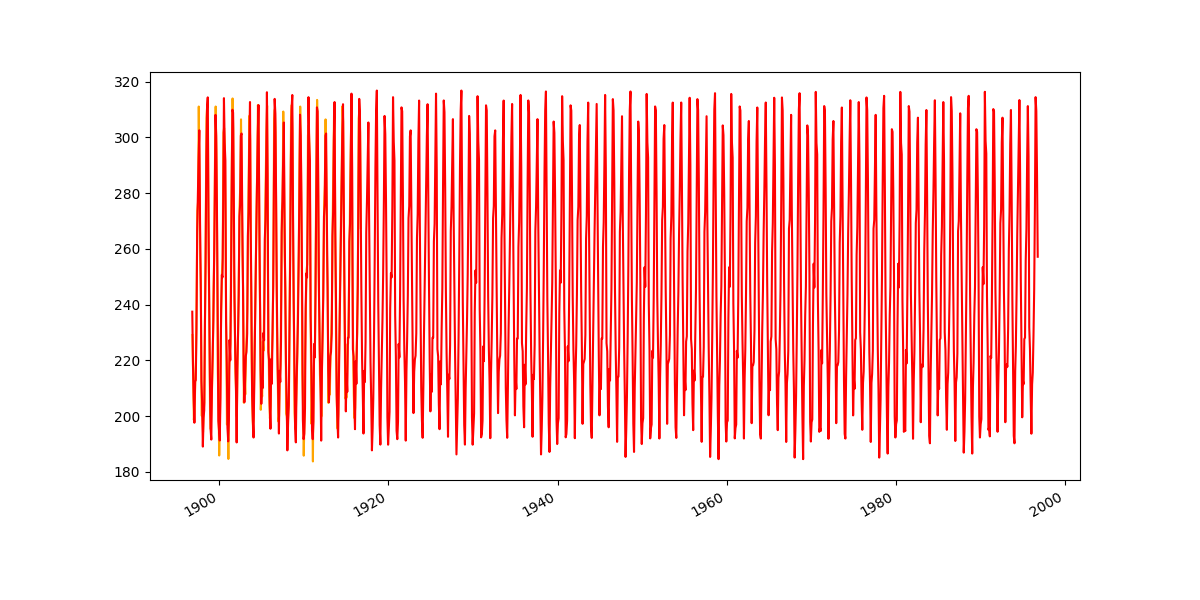

In [14]:
# Plot the LW radiation
fig, ax = plt.subplots(figsize=(12, 6))
model_lwdown.plot(ax=ax, label='LWdown model', color='orange')
forcing_lwdown_month.plot(ax=ax, label='LWdown forcing', color='red')

In [ ]:
vegetation_data = land_month[['snow_depth','precip','Tgrnd','height','lai']].isel(grid_index=0).to_dataframe()
vegetation_data.index = vegetation_data.index.to_datetimeindex()

# Drop all extraneous columns
vegetation_data = vegetation_data[['snow_depth','precip','Tgrnd','height','lai']]

Compare precip to verify that the forcing is correct.

In [ ]:
forcing_precip = get_spinup_forcing(forcing_10yr, 'precip')
forcing_precip_month = forcing_precip.resample('MS').mean()

# Shift index forward 15 days to match the land month data
forcing_precip_month.index = forcing_precip_month.index + pd.DateOffset(days=15)

In [ ]:
# Plot precip datasets on the same plot
fig, ax = plt.subplots(figsize=(12, 6))
forcing_precip_month.plot(ax=ax, label='Forcing Precipitation', color='blue')
vegetation_data['precip'].plot(ax=ax, label='Vegetation Precipitation', color='orange')

The two datasets should basically be the same, although the land_month data might be averaged differently with a julian calendar. At least they are quite similar.

In [ ]:
vegetation_data.plot(subplots=True, figsize=(10, 6), title='Vegetation Data for ' + snotel_site)

- Vegetation growth is bizaar for the first 50 years or so, could this be due to soil properties or a model bug?

### Analysis: Soil

In [ ]:
# Function for extracting soil data
def extract_soil_data(soil_var) -> pd.DataFrame:
    soil_data = land_month[[soil_var]].isel(grid_index=0).to_dataframe()
    soil_data_df = soil_data.reset_index().pivot(index='time', columns='zfull_soil', values=soil_var)
    soil_data_df.columns.name = 'Depth'
    soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
    soil_data_df.columns = [f"{col:03.2f}" for col in soil_data_df.columns]
    return soil_data_df

In [ ]:
# Extract the soil data at different depths
soil_T = extract_soil_data('soil_T')
soil_liq = extract_soil_data('soil_liq')
soil_ice = extract_soil_data('soil_ice')

In [ ]:
# Get air temperature from forcing data
Tair_month = Tair.resample('MS').mean()

In [ ]:
# Merge in ground surface temperature and air temperature
soil_T['Tgrnd'] = vegetation_data['Tgrnd']
#soil_T['Tair'] = Tair_month.to_numpy()

# Change soil_T values from Kelvin to Celsius
soil_T = soil_T - 273.15

# Add snow depth to soil_T dataframe
soil_T['snow_depth'] = vegetation_data['snow_depth']

In [ ]:
soil_T[['snow_depth','Tgrnd','0.01','1.20','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Temperature at Different Depths for ' + snotel_site)

This data doesn't make sense. There is almost a meter of snow on the ground early on but the ground surface is at -20 degrees C. This is not possible, the ground surface should be at 0 degrees C if there is snow on the ground.

In [ ]:
soil_ice[['0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Ice at Different Depths for ' + snotel_site)

In [ ]:
# Add precip to soil_liq dataframe
soil_liq['precip'] = vegetation_data['precip']

In [ ]:
soil_liq[['precip','0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Liquid Water at Different Depths for ' + snotel_site)

Liquid water looks fairly normal except deeper where there appears to be permafrost for a long time.

What is the fractional snow cover?

In [ ]:
# Get the fractional snow cover from the land month data
fsc = land_month['snow_frac'].isel(grid_index=0).to_dataframe()